Saving Unemployment in India.csv to Unemployment in India.csv
DATASET OVERVIEW
Shape: (740, 9)

First five rows:


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Area,Year,Month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019,5
290,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural,2019,5
276,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural,2019,5
257,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural,2019,5
243,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural,2019,5



SUMMARY STATISTICS


,Unemployment_Rate
count,740.000000
mean,11.787946
std,10.721298
min,0.000000
25%,4.657500
50%,8.350000
75%,15.887500
max,76.740000


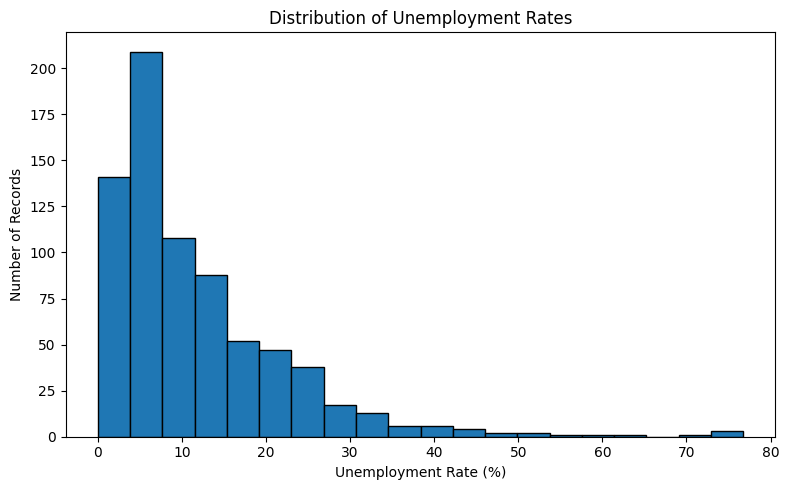

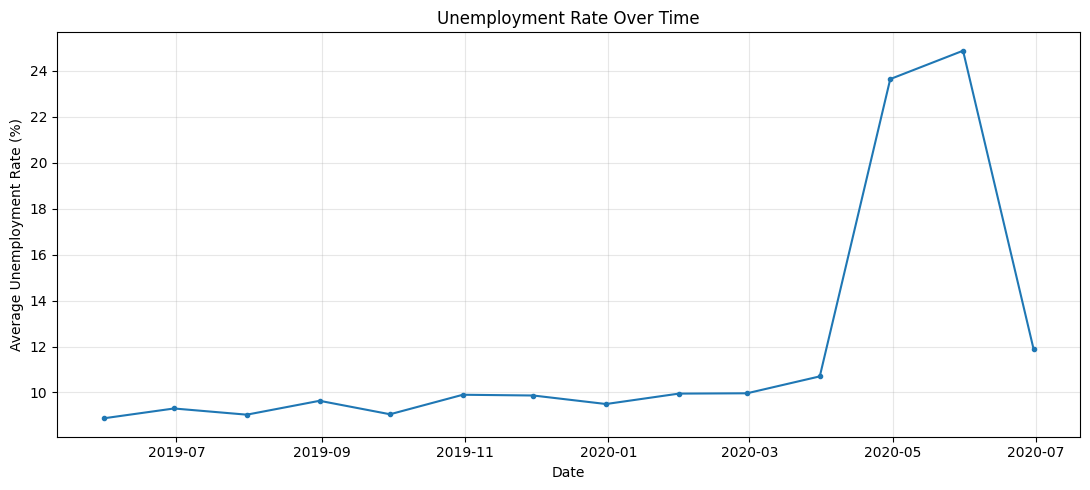


Average unemployment rate by region:


,Average_Rate
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


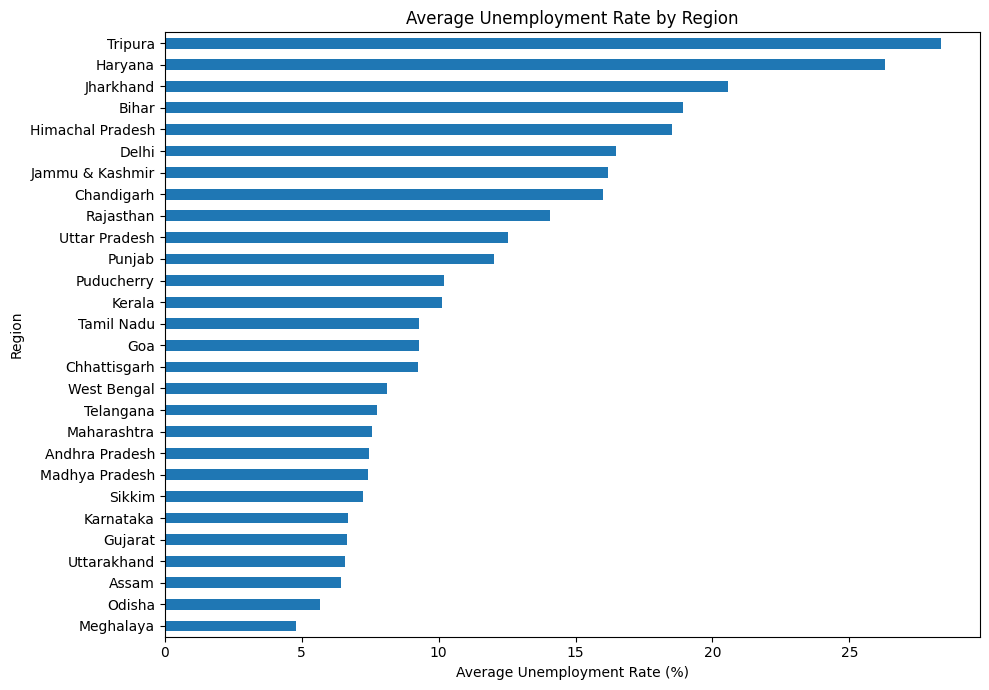


Average unemployment rate by area:


,Average_Rate
Area,
Rural,10.324791
Urban,13.166614


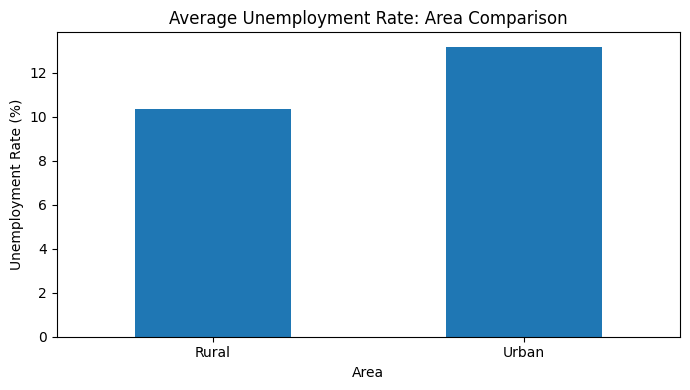


COVID-19 PERIOD COMPARISON
Before March 2020: 9.51%
March-Dec 2020:    17.77%
Difference:        +8.26 percentage points


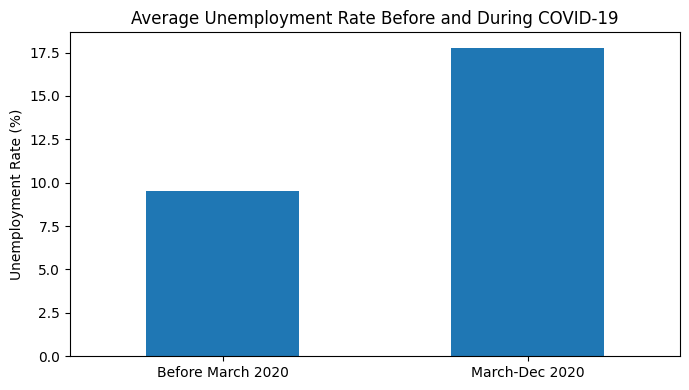


Task 2 analysis completed successfully!
Saved: cleaned_unemployment_data.csv
Saved: analysis_summary.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# CodeAlpha Internship - Task 2
# Unemployment Analysis with Python

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload the internship dataset CSV
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a CSV dataset.")

df = pd.read_csv(csv_files[0])

# 2. Clean column names
df.columns = (
    df.columns.str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Standardize common column names
rename_map = {}
for col in df.columns:
    lower = col.lower()
    if lower == "date":
        rename_map[col] = "Date"
    elif lower == "region":
        rename_map[col] = "Region"
    elif "estimated unemployment rate" in lower:
        rename_map[col] = "Unemployment_Rate"
    elif "estimated employed" in lower:
        rename_map[col] = "Employed"
    elif "estimated labour participation rate" in lower:
        rename_map[col] = "Labour_Participation_Rate"
    elif lower == "area":
        rename_map[col] = "Area"

df.rename(columns=rename_map, inplace=True)

if "Unemployment_Rate" not in df.columns:
    raise ValueError(
        "Unemployment-rate column not found. "
        "Please check that you uploaded the correct internship dataset."
    )

# 3. Convert numeric and date columns
df["Unemployment_Rate"] = pd.to_numeric(
    df["Unemployment_Rate"].astype(str).str.replace("%", "", regex=False).str.strip(),
    errors="coerce"
)

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(
        df["Date"].astype(str).str.strip(),
        dayfirst=True,
        errors="coerce"
    )

df.dropna(subset=["Unemployment_Rate"], inplace=True)

if "Date" in df.columns:
    df.dropna(subset=["Date"], inplace=True)
    df = df.sort_values("Date")
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month

print("DATASET OVERVIEW")
print("Shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nSUMMARY STATISTICS")
display(df["Unemployment_Rate"].describe())

# 4. Overall unemployment-rate distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Unemployment_Rate"], bins=20, edgecolor="black")
plt.title("Distribution of Unemployment Rates")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# 5. Trend over time
if "Date" in df.columns:
    trend = df.groupby("Date")["Unemployment_Rate"].mean()

    plt.figure(figsize=(11, 5))
    plt.plot(trend.index, trend.values, marker="o", markersize=3)
    plt.title("Unemployment Rate Over Time")
    plt.xlabel("Date")
    plt.ylabel("Average Unemployment Rate (%)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# 6. Regional comparison
if "Region" in df.columns:
    regional = (
        df.groupby("Region")["Unemployment_Rate"]
        .mean()
        .sort_values(ascending=False)
    )

    print("\nAverage unemployment rate by region:")
    display(regional.to_frame("Average_Rate"))

    plt.figure(figsize=(10, 7))
    regional.sort_values().plot(kind="barh")
    plt.title("Average Unemployment Rate by Region")
    plt.xlabel("Average Unemployment Rate (%)")
    plt.tight_layout()
    plt.show()

# 7. Urban versus rural comparison
if "Area" in df.columns:
    area_rates = df.groupby("Area")["Unemployment_Rate"].mean()

    print("\nAverage unemployment rate by area:")
    display(area_rates.to_frame("Average_Rate"))

    area_rates.plot(kind="bar", figsize=(7, 4))
    plt.title("Average Unemployment Rate: Area Comparison")
    plt.ylabel("Unemployment Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 8. COVID-19 period comparison
if "Date" in df.columns:
    before_covid = df.loc[
        df["Date"] < "2020-03-01", "Unemployment_Rate"
    ]
    during_covid = df.loc[
        (df["Date"] >= "2020-03-01") &
        (df["Date"] <= "2020-12-31"),
        "Unemployment_Rate"
    ]

    print("\nCOVID-19 PERIOD COMPARISON")
    if not before_covid.empty and not during_covid.empty:
        print(f"Before March 2020: {before_covid.mean():.2f}%")
        print(f"March-Dec 2020:    {during_covid.mean():.2f}%")
        print(
            "Difference:        "
            f"{during_covid.mean() - before_covid.mean():+.2f} percentage points"
        )

        comparison = pd.Series({
            "Before March 2020": before_covid.mean(),
            "March-Dec 2020": during_covid.mean()
        })
        comparison.plot(kind="bar", figsize=(7, 4))
        plt.title("Average Unemployment Rate Before and During COVID-19")
        plt.ylabel("Unemployment Rate (%)")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough data for both periods.")

# 9. Save cleaned data and analysis results
df.to_csv("cleaned_unemployment_data.csv", index=False)

with open("analysis_summary.txt", "w") as f:
    f.write("CodeAlpha Task 2: Unemployment Analysis\n")
    f.write(f"Records analyzed: {len(df)}\n")
    f.write(
        f"Mean unemployment rate: "
        f"{df['Unemployment_Rate'].mean():.2f}%\n"
    )
    f.write(
        f"Median unemployment rate: "
        f"{df['Unemployment_Rate'].median():.2f}%\n"
    )

print("\nTask 2 analysis completed successfully!")
print("Saved: cleaned_unemployment_data.csv")
print("Saved: analysis_summary.txt")

# Download the generated files
files.download("cleaned_unemployment_data.csv")
files.download("analysis_summary.txt")
